This serves to give estimates for the experiment heat equation.
I will try to keep it as general as possible to adjust quickly. Functions are implemented in heat_equation.py
Units are chosen in si. Use meters as in cm the diffusivity values change the order of magnitude a lot !

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from heat_equation import *

The following block takes an array of measurement points at time $t = 0$ and finds the solution at a later time $t = t_{final}$
Example setup for the block at roughly 80C and rod at room temperature

intial cos basis coefficients: [310.    19.32  17.32  14.14  10.     5.18]
final cos basis coefficients: [3.100e+02 6.312e+00 1.970e-01 1.000e-03 0.000e+00 0.000e+00]


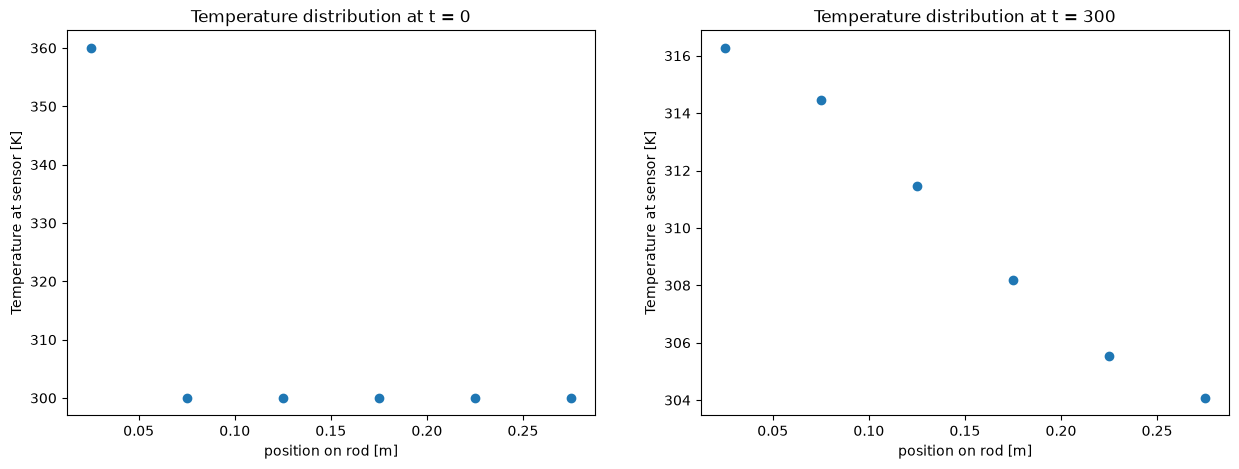

In [21]:
#initial_state = [360, 300, 300, 300, 300, 300] #temperature values measured at nodes
N = 6
L = 0.3
t_final = 300
#coeffs = np.array([300, 20, 20, 20, 20, 20], dtype = float)
T_initial = np.array([360, 300, 300, 300, 300, 300], dtype = float) #temperature values measured at nodes
delta_x = L / N
x = delta_x * np.arange(N) + (delta_x/2) #get a vector with the positions implemented
coeffs = get_coeffs_cos_basis(T_initial, x)
coeffs_prop = lossless_propagation_1D(coeffs, t_final) #propagate coeffs in time
print(f"intial cos basis coefficients: {np.round(coeffs, 2)}")
print(f"final cos basis coefficients: {np.round(coeffs_prop, 3)}") 

fig, ax = plt.subplots(1, 2, figsize = (15, 5))
ax[0].scatter(x, T_initial)
ax[0].set_xlabel("position on rod [m]")
ax[0].set_ylabel("Temperature at sensor [K]")
ax[0].set_title(f"Temperature distribution at t = {0}")
ax[1].scatter(x, evaluate_cosine_sum(coeffs_prop, x, L = L))
ax[1].set_xlabel("position on rod [m]")
ax[1].set_ylabel("Temperature at sensor [K]")
ax[1].set_title(f"Temperature distribution at t = {t_final}")
plt.show()

As you can see we need to make the measurement rather quickly to not have the earliest modes decay a lot. 